# 02 · Exploratory data analysis

Before modelling we want to know three things: which metadata fields carry signal, what the images look like,
and, once a model exists, which malignant lesions it still ranks too low. The last question matters most, because
pAUC80 is decided by the malignant lesions with the lowest scores.

_This model was developed for a research competition and is not a medical device._

In [1]:
# Setup: every path comes from configs/final.yaml (milk10k.config); nothing here downloads data.
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RELEASE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(RELEASE / "src") not in sys.path:
    sys.path.insert(0, str(RELEASE / "src"))  # works without `pip install -e .`
from milk10k.config import load_config
from milk10k.metrics import CLASSES, MALIGNANT

cfg = load_config()
DATA = cfg["paths"]["data_dir"]  # prepared MILK10k (data/README.md); override with MILK10K_DATA_DIR

# "data:<file>" = under DATA; anything else is relative to the release root.
INPUTS = {
    "train_meta": "data:train_metadata.csv",
    "folds": "data/folds.csv",
    "image_sizes": "results/tables/01_image_sizes.csv",
    "oof_final": "results/oof/final-P1a-kg_oof.csv",
    "oof_s42": "results/oof/P1a-kg-s42_oof.csv",
    "oof_s43": "results/oof/P1a-kg-s43_oof.csv",
    "oof_s44": "results/oof/P1a-kg-s44_oof.csv"
}
OUTPUTS = {
    "fig_age": "results/figures/02_age_by_malignancy.png",
    "fig_site": "results/figures/02_class_by_site.png",
    "table_rates": "results/tables/02_malignancy_rates.csv",
    "table_hard_check": "results/tables/02_hard_positive_check.csv",
    "table_hard_classes": "results/tables/02_hard_positive_classes.csv",
    "table_inversions": "results/tables/02_benign_inversions.csv",
    "fig_hard": "results/figures/02_hard_positive_classes.png"
}


def inp(key):
    v = INPUTS[key]
    return DATA / v[5:] if v.startswith("data:") else RELEASE / v


def out(key):
    p = RELEASE / OUTPUTS[key]
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def savefig(key):
    plt.tight_layout()
    plt.savefig(out(key), dpi=120)
    plt.show()


missing = [k for k in INPUTS if not inp(k).exists()]
import os  # noqa: E402
print("data dir from:", "MILK10K_DATA_DIR" if os.environ.get("MILK10K_DATA_DIR") else "configs/final.yaml")
print("checkpoints from:", "MILK10K_CHECKPOINT_DIR" if os.environ.get("MILK10K_CHECKPOINT_DIR") else "configs/final.yaml")
print("missing inputs:", missing or "none")

data dir from: MILK10K_DATA_DIR
checkpoints from: configs/final.yaml
missing inputs: none


## 1. Age
Is age informative, and how often is it missing?

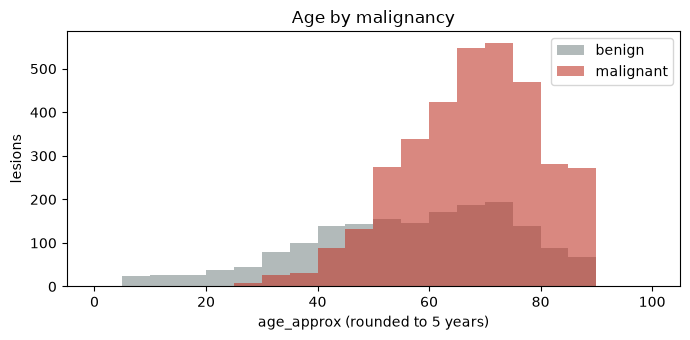

missing age: 20


In [2]:
train = pd.read_csv(inp("train_meta"))
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, 101, 5)
for y, label, color in ((0, "benign", "#7f8c8d"), (1, "malignant", "#c0392b")):
    ax.hist(train.loc[train.target_binary == y, "age_approx"].dropna(), bins=bins, alpha=0.6, label=label, color=color)
ax.set_xlabel("age_approx (rounded to 5 years)")
ax.set_ylabel("lesions")
ax.legend()
ax.set_title("Age by malignancy")
savefig("fig_age")
print("missing age:", int(train.age_approx.isna().sum()))

Malignant lesions sit visibly further to the right of the age axis than benign ones, so age carries signal.
Age is missing for only 20 lesions, so the `age_missing` flag will rarely fire.

## 2. Malignancy rate by sex, site and skin-tone code
Do the categorical fields shift the base rate? Several strata are tiny, so we show the count next to every rate.

In [3]:
rates = []
for col in ("sex", "anatomical_site_general", "fitzpatrick_type"):
    g = train.groupby(train[col].astype("string").fillna("missing")).target_binary
    rates.append(pd.DataFrame({"feature": col, "lesions": g.size(), "malignant_rate": g.mean().round(3)}))
rates = pd.concat(rates).rename_axis("value").reset_index()
rates.to_csv(out("table_rates"), index=False)
rates

,value,feature,lesions,malignant_rate
0,female,sex,2088,0.621
1,male,sex,3152,0.685
2,foot,anatomical_site_general,23,0.870
3,hand,anatomical_site_general,72,0.681
4,head/neck,anatomical_site_general,1491,0.683
5,lower extremity,anatomical_site_general,1023,0.639
6,missing,anatomical_site_general,31,0.323
7,oral/genital,anatomical_site_general,8,0.125
8,trunk,anatomical_site_general,1925,0.640
9,upper extremity,anatomical_site_general,667,0.705


Men have a slightly higher malignant rate than women (0.685 vs 0.621). Site matters more, but the extreme rates
sit on very small strata: foot is 0.870 on 23 lesions and oral/genital 0.125 on 8. The skin-tone codes split
sharply. Codes 1–3 are mostly benign (0.167, 0.352, 0.407), while codes 4–6 are 0.68–0.70 malignant. The small
code 1–2 group therefore has a different case mix from everyone else, which matters when we read FairGap later.

## 3. Diagnosis by anatomical site
Site could act as a shortcut for the diagnosis. How strongly are the two linked?

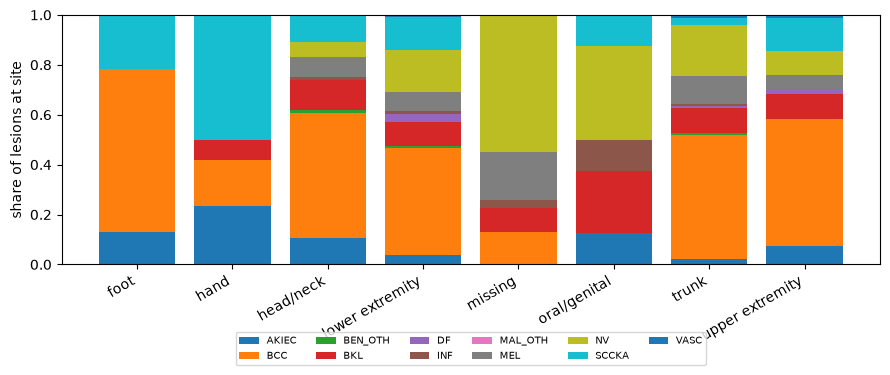

anatomical_site_general,foot,hand,head/neck,lower extremity,missing,oral/genital,trunk,upper extremity
diagnostic_class_11,,,,,,,,
AKIEC,3,17,157,37,0,1,40,48
BCC,15,13,745,442,4,0,961,342
BEN_OTH,0,0,21,8,0,0,15,0
BKL,0,6,176,97,3,2,194,66
DF,0,0,0,34,0,0,9,9
INF,0,0,20,10,1,1,16,2
MAL_OTH,0,0,1,2,0,0,6,0
MEL,0,0,117,78,6,0,209,40
NV,0,0,93,173,17,3,396,64


In [4]:
ct = pd.crosstab(train.diagnostic_class_11, train.anatomical_site_general.fillna("missing")).reindex(CLASSES)
share = ct / ct.sum()
fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(share.shape[1])
for c in share.index:
    ax.bar(share.columns, share.loc[c], bottom=bottom, label=c)
    bottom += share.loc[c].to_numpy()
ax.set_ylabel("share of lesions at site")
ax.legend(ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.xticks(rotation=30, ha="right")
savefig("fig_site")
ct

BCC dominates both the trunk (961 lesions) and head/neck (745), and DF appears almost only on the lower extremity
(34 of 52). Site and diagnosis are entangled, so any per-site error rate is partly a class-mix effect.

## 4. Image geometry
How much do the images vary before we resize them to 288 px? (Sizes come from the header scan in notebook 01.)

In [5]:
sizes = pd.read_csv(inp("image_sizes"))
sizes["aspect"] = sizes.width / sizes.height
sizes.groupby(["split", "modality"]).agg(images=("aspect", "size"), width_median=("width", "median"),
                                          height_median=("height", "median"), aspect_median=("aspect", "median"),
                                          aspect_min=("aspect", "min"), aspect_max=("aspect", "max"))

images  width_median  height_median  aspect_median  \
split modality                                                       
test  clinical     479         600.0          450.0       1.333333   
      derm         479         600.0          450.0       1.333333   
train clinical    5240         600.0          450.0       1.333333   
      derm        5240         600.0          450.0       1.333333   

                aspect_min  aspect_max  
split modality                          
test  clinical    1.333333    1.333333  
      derm        1.333333    1.333333  
train clinical    1.333333    1.333333  
      derm        1.333333    1.333333

Every image, in both modalities and both splits, is 600×450 (aspect 1.333). Resizing dermoscopy to a 288×288
square therefore stretches every lesion by the same factor, and the clinical letterbox always pads the same
share of the canvas. Geometry does not vary between lesions, so it cannot explain why some are hard.

## 5. Example lesions
What do the two views look like for the classes that are most often confused with each other? Below is one lesion
each of MEL, NV, BCC, BKL, AKIEC and SCCKA, with dermoscopy on top and the clinical close-up underneath. The images
are shown small, as an embedded JPEG, and are not saved to `results/`.

<release>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


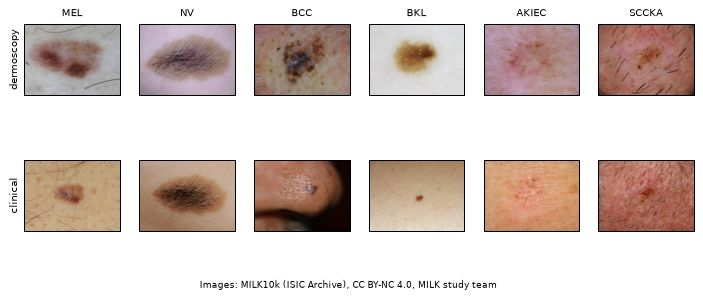

In [6]:
SHOW_IMAGES = True  # small embedded JPEG; never saved to results/
if SHOW_IMAGES:
    import io

    from IPython.display import Image, display

    from milk10k.dataset import read_rgb

    shown = ["MEL", "NV", "BCC", "BKL", "AKIEC", "SCCKA"]
    picks = [train[train.diagnostic_class_11 == c].iloc[0] for c in shown]  # first lesion of each class (file order)
    fig, axes = plt.subplots(2, len(picks), figsize=(1.6 * len(picks), 3.6), squeeze=False)
    for j, r in enumerate(picks):
        axes[0, j].imshow(read_rgb(str(DATA / r.derm_image_path)))
        axes[0, j].set_title(r.diagnostic_class_11, fontsize=8)
        if isinstance(r.clinical_image_path, str) and r.clinical_image_path:
            axes[1, j].imshow(read_rgb(str(DATA / r.clinical_image_path)))
        for a in axes[:, j]:
            a.set_xticks([])
            a.set_yticks([])
    axes[0, 0].set_ylabel("dermoscopy", fontsize=8)
    axes[1, 0].set_ylabel("clinical", fontsize=8)
    fig.text(0.5, 0.0, "Images: MILK10k (ISIC Archive), CC BY-NC 4.0, MILK study team", ha="center", fontsize=7)
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=90, bbox_inches="tight", pil_kwargs={"quality": 80})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format="jpeg"))

## 6. Which malignant lesions does the final model rank too low?
pAUC80 only looks at the region where at least 80% of malignant lesions are caught. We call a malignant lesion
*hard* when its out-of-fold score falls below the cut that keeps 80% of malignant lesions above it
(`milk10k.evaluation.tail_threshold`).

If the same lesions are hard for every seed, adding seeds will not help; if the hard set changes from seed to seed,
ensembling should. We recompute the counts from the out-of-fold predictions and compare them with the values we
logged when we first ran this analysis (`docs/experiment_log.md`).

In [7]:
from milk10k.evaluation import benign_inversions, hard_positive_flags, load_oof, load_solution

sol = load_solution(DATA, inp("folds"))
labels, y_cls = sol.target_binary.to_numpy(), sol.diagnostic_class_11.to_numpy()
runs = {"final-P1a-kg": "oof_final", **{f"P1a-kg-s{s}": f"oof_s{s}" for s in (42, 43, 44)}}
prob = {r: load_oof(inp(k), sol).target_binary.to_numpy() for r, k in runs.items()}
hard = {r: hard_positive_flags(labels, p) for r, p in prob.items()}
seed_count = sum(hard[f"P1a-kg-s{s}"].astype(int) for s in (42, 43, 44))
final_hard = hard["final-P1a-kg"]
computed = {
    "malignant lesions": int(labels.sum()),
    "final hard": int(final_hard.sum()),
    "final hard, hard in all 3 seeds": int((final_hard & (seed_count == 3)).sum()),
    "final hard, hard in >=2 seeds": int((final_hard & (seed_count >= 2)).sum()),
    "union of the 3 seed tails": int((seed_count > 0).sum()),
    "hard in exactly 1 seed": int((seed_count == 1).sum()),
    "hard in exactly 2 seeds": int((seed_count == 2).sum()),
    "hard in exactly 3 seeds": int((seed_count == 3).sum()),
}
logged = {"malignant lesions": 3454, "final hard": 690, "final hard, hard in all 3 seeds": 427,
         "final hard, hard in >=2 seeds": 621, "union of the 3 seed tails": 1000, "hard in exactly 1 seed": 357,
         "hard in exactly 2 seeds": 216, "hard in exactly 3 seeds": 427}  # when first analysed (docs/experiment_log.md)
check = pd.DataFrame({"computed": computed, "logged": logged})
check["match"] = check.computed == check.logged
check.to_csv(out("table_hard_check"))
check

,computed,logged,match
malignant lesions,3454,3454,True
final hard,690,690,True
"final hard, hard in all 3 seeds",427,427,True
"final hard, hard in >=2 seeds",621,621,True
union of the 3 seed tails,1000,1000,True
hard in exactly 1 seed,357,357,True
hard in exactly 2 seeds,216,216,True
hard in exactly 3 seeds,427,427,True


All eight counts match the log. The final ensemble leaves 690 of 3,454 malignant lesions below the cut. Of these,
427 (61.9%) are hard for all three seeds and 621 for at least two. The misses are largely shared, so they belong to
the model, not to an unlucky seed.

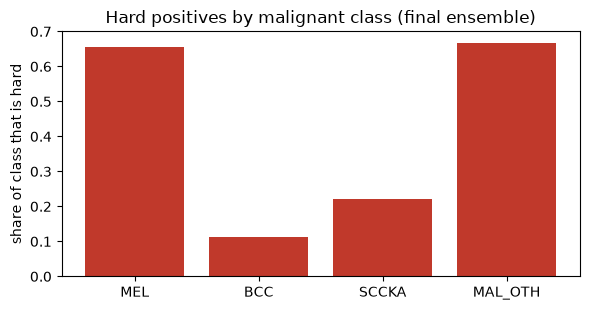

,malignant,final_hard,hard_in_all_3_seeds,hard_rate
MEL,450,295,216,0.656
BCC,2522,285,154,0.113
SCCKA,473,104,53,0.220
MAL_OTH,9,6,4,0.667


In [8]:
comp = pd.DataFrame({"malignant": pd.Series(y_cls[labels == 1]).value_counts(),
                     "final_hard": pd.Series(y_cls[final_hard]).value_counts(),
                     "hard_in_all_3_seeds": pd.Series(y_cls[final_hard & (seed_count == 3)]).value_counts()}).fillna(0).astype(int)
comp["hard_rate"] = (comp.final_hard / comp.malignant).round(3)
comp = comp.sort_values("final_hard", ascending=False)
comp.to_csv(out("table_hard_classes"))
# logged: MEL 295/450, BCC 285/2,522, SCCKA 104/473, MAL_OTH 6/9
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(comp.index, comp.hard_rate, color="#c0392b")
ax.set_ylabel("share of class that is hard")
ax.set_title("Hard positives by malignant class (final ensemble)")
savefig("fig_hard")
comp

Melanoma is the weak spot: 295 of 450 melanomas (65.6%) are hard, 216 of them for all three seeds. BCC
contributes almost as many hard cases (285), but only because it is so common: just 11.3% of BCCs are hard.
MAL_OTH has 9 lesions, too few to read anything into.

Which benign lesions outrank them? We count strict pairs in which a benign lesion scores above a hard malignant one.

In [9]:
inv = benign_inversions(y_cls, labels, prob["final-P1a-kg"], final_hard)
inv.to_csv(out("table_inversions"), index=False)
inv

,benign_class,benign_lesions,inversions,share_of_possible_pairs
0,BKL,544,222424,0.592562
1,NV,746,140570,0.273089
2,AKIEC,303,125323,0.599431
3,INF,50,13285,0.385072
4,DF,52,11308,0.315162
5,BEN_OTH,44,9775,0.321970
6,VASC,47,5571,0.171785


BKL, NV and AKIEC dominate the inversions, with 222,424, 140,570 and 125,323 pairs. BKL and AKIEC outrank
about 60% of all possible hard-malignant pairs (59.3% and 59.9%), NV 27.3%. These benign classes are exactly the
ones that look like melanoma and keratinocyte cancers.

## 7. Is preprocessing destroying the clues?
A natural suspect for the hard cases is the input pipeline: the 288-px resize, the random crops or the aspect
distortion. We compared 40 persistent-hard malignant lesions with 40 easy ones matched on class, site and
skin-tone code, looking at the native image, the evaluation view and two training augmentations of each.

Nothing separated the two groups. The review flagged something else instead: the `GaussNoise` augmentation
visibly corrupts training images in both streams. We confirmed that the noise survives into the normalised training
tensors (0.634–0.976 RMS). Removing it became our one controlled follow-up experiment, and it turned out to be a
negative result (notebook 06, `docs/experiment_log.md`). The gallery is not reproduced here; it was reviewed by eye only.

## Takeaways
- Malignancy is common (66% of lesions) and varies with site and skin-tone code: real signal, but confounded with the class mix.
- All images are 600×450, so the preprocessing distortion is identical for every lesion.
- The final model's misses are concentrated and stable across seeds: melanoma, ranked below BKL, NV and AKIEC. Representation and ranking, not more seeds or a different crop, are where improvements should aim.

Next, notebook 03 shows exactly how images and metadata become model inputs.